<a href="https://colab.research.google.com/github/katiyardivyanshu08-bit/Retail_Pulse_Project_/blob/main/3_Retail_Model_Reg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [95]:
import pandas as pd
import numpy as np
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')
# Getting access
# from google.colab import drive
# drive.mount('/content/drive')
# Sklearn
from sklearn.model_selection import KFold, cross_validate
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [96]:
url = "https://raw.githubusercontent.com/katiyardivyanshu08-bit/Retail_Pulse_Project_/main/Data/Main_Clean.csv"
df = pd.read_csv(url)
df.head()

,CustomerID,Age,Gender,Region,ProductCategory,AnnualIncome,PurchaseFrequency,AnnualPurchaseAmount,LastPurchaseDate,CustomerTenure,DiscountUsage,ReturnRate,CustomerSegment
0,204242,50,male,north,beauty,57328.90,4.0,10206.51,2025-09-07,3.16,0.3790,0.0929,regular
1,299677,36,male,east,clothing,66674.05,1.0,5497.05,2025-11-05,7.11,0.2153,0.0251,regular
2,240200,37,male,central,electronics,39673.95,2.0,5850.72,2025-10-20,6.43,0.1474,0.1273,budget
3,232815,36,male,south,clothing,70271.46,11.0,10174.37,2025-12-01,2.50,0.1379,0.0133,regular
4,508698,30,female,west,home & kitchen,67653.56,6.0,10441.58,2025-12-30,3.21,0.0958,0.0853,regular


In [98]:
X = df.drop(
    columns=[
        "AnnualPurchaseAmount",
        "CustomerID",
        "CustomerSegment",
        "LastPurchaseDate"
    ],
    errors="ignore"
)
y = df["AnnualPurchaseAmount"]

In [99]:
# Remove rows with missing target values
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

In [100]:
# cat_pipe = Pipeline([
#     ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
#     ("encoder", OneHotEncoder(handle_unknown="ignore"))
# ])

# # Model 1: Without PCA
# num_pipe1 = Pipeline([
#     ("imputer", SimpleImputer(strategy="median")),
#     ("transform", PowerTransformer(method="yeo-johnson"))
# ])

# pre1 = ColumnTransformer([
#     ("num", num_pipe1, num_cols),
#     ("cat", cat_pipe, cat_cols)
# ])

# model1 = Pipeline([
#     ("preprocessor", pre1),
#     ("regressor", LinearRegression())
# ])

# # Model 2: With PCA
# num_pipe2 = Pipeline([
#     ("imputer", SimpleImputer(strategy="median")),
#     ("transform", PowerTransformer(
#         method="yeo-johnson", standardize=False
#     )),
#     ("scaler", StandardScaler()),
#     ("pca", PCA(n_components=0.95))
# ])

# pre2 = ColumnTransformer([
#     ("num", num_pipe2, num_cols),
#     ("cat", cat_pipe, cat_cols)
# ])

# model2 = Pipeline([
#     ("preprocessor", pre2),
#     ("regressor", LinearRegression())
# ])

# # Compare 5-fold cross-validation R²
# scores1 = cross_val_score(
#     model1, X_train, y_train, cv=5,
#     scoring="r2", n_jobs=-1
# )

# scores2 = cross_val_score(
#     model2, X_train, y_train, cv=5,
#     scoring="r2", n_jobs=-1
# )

# print("Without PCA:", round(scores1.mean(), 4))
# print("With PCA:", round(scores2.mean(), 4))

# Without PCA: 0.5885
# With PCA: 0.5885

In [101]:
# # Categorical preprocessing
# cat_pipe = Pipeline([
#     ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
#     ("encoder", OneHotEncoder(handle_unknown="ignore"))
# ])

# # Model 1: Without PowerTransformer
# num_pipe1 = Pipeline([
#     ("imputer", SimpleImputer(strategy="median")),
#     ("scaler", StandardScaler())
# ])

# # Model 2: With PowerTransformer
# num_pipe2 = Pipeline([
#     ("imputer", SimpleImputer(strategy="median")),
#     ("transform", PowerTransformer(method="yeo-johnson"))
# ])

# def make_model(num_pipe):
#     preprocessor = ColumnTransformer([
#         ("num", num_pipe, num_cols),
#         ("cat", cat_pipe, cat_cols)
#     ])

#     return Pipeline([
#         ("preprocessor", preprocessor),
#         ("regressor", LinearRegression())
#     ])

# models = {
#     "Without PowerTransformer": make_model(num_pipe1),
#     "With PowerTransformer": make_model(num_pipe2)
# }

# for name, model in models.items():
#     scores = cross_validate(
#         model,
#         X_train,
#         y_train,
#         cv=5,
#         scoring={
#             "r2": "r2",
#             "rmse": "neg_root_mean_squared_error"
#         },
#         n_jobs=-1
#     )

#     print(f"\n{name}")
#     print("Mean CV R²:", round(scores["test_r2"].mean(), 4))
#     print("Mean CV RMSE:", round(-scores["test_rmse"].mean(), 2))


# Without PowerTransformer
# Mean CV R²: 0.6528
# Mean CV RMSE: 5561.28

# With PowerTransformer
# Mean CV R²: 0.5885
# Mean CV RMSE: 6054.9

In [102]:
# Train the selected model without PowerTransformer or PCA

In [103]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

num_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Columns:", num_cols)
print("Categorical Columns:", cat_cols)
print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))

Numerical Columns: ['Age', 'AnnualIncome', 'PurchaseFrequency', 'CustomerTenure', 'DiscountUsage', 'ReturnRate', 'Recency']
Categorical Columns: ['Gender', 'Region', 'ProductCategory']
Training Rows: 399200
Testing Rows: 99800


In [104]:
# Numerical preprocessing
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])

# Combine both preprocessors
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

# Complete model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [105]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "r2": "r2",
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error"
    },
    n_jobs=-1
)

print("Fold R² Scores:", np.round(cv_scores["test_r2"], 4))
print("Mean CV R²:", round(cv_scores["test_r2"].mean(), 4))

print("Mean CV RMSE:",round(-cv_scores["test_rmse"].mean(), 2))
print("Mean CV MAE:",round(-cv_scores["test_mae"].mean(), 2))

Fold R² Scores: [0.6453 0.6493 0.662  0.6556 0.6521]
Mean CV R²: 0.6528
Mean CV RMSE: 5560.99
Mean CV MAE: 3634.65


In [106]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Test R²:", round(r2_score(y_test, y_pred), 4))
print("Test RMSE:",round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("Test MAE:",round(mean_absolute_error(y_test, y_pred), 2))

Test R²: 0.6571
Test RMSE: 5483.31
Test MAE: 3605.24


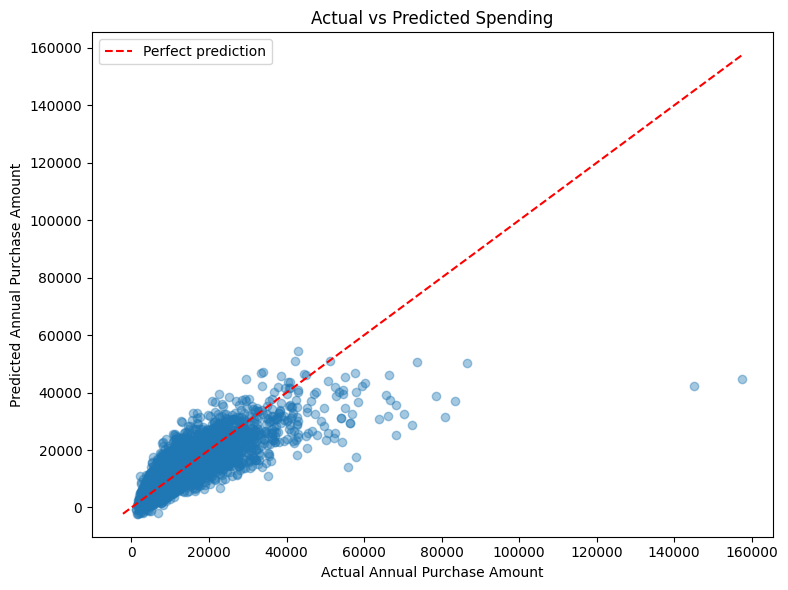

In [107]:
plot_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

plot_df = plot_df.sample(
    min(5000, len(plot_df)),
    random_state=42
)

low = min(plot_df["Actual"].min(), plot_df["Predicted"].min())
high = max(plot_df["Actual"].max(), plot_df["Predicted"].max())

plt.figure(figsize=(8, 6))

plt.scatter(
    plot_df["Actual"],
    plot_df["Predicted"],
    alpha=0.4
)

plt.plot(
    [low, high],
    [low, high],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Annual Purchase Amount")
plt.ylabel("Predicted Annual Purchase Amount")
plt.title("Actual vs Predicted Spending")
plt.legend()
plt.tight_layout()
plt.show()

In [108]:
# import joblib
# joblib.dump(model, "retailpulse_lr_pipeline.joblib")